# 02c — Preparación de modelado

Bloques 6–8 del cuaderno 02: MLP (aparcado), PCA de CLC y normalización.

## Imports (celda única del cuaderno)

In [1]:
# Imports del cuaderno (celda única) — todas las dependencias aquí; las demás celdas no importan nada.
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from wildfire.data.io import load_csv, save_csv
from wildfire.processing.pca_weather import AddWindCircular
from wildfire.processing.occurrence import SATELLITE_BLOCKLIST


# 6 — One-hot encoding y red neuronal

Este notebook usa nuestro para preparar variables categóricas con one-hot encoding y entrenar una red neuronal de clasificación mediante `MLPClassifier` de scikit-learn. Por defecto, predice la columna `confidence_cat`, que contiene la clase de la detección. Puedes cambiar `TARGET` en la primera celda si tu objetivo es otra variable categórica.

Se separan los datos en entrenamiento y prueba antes de ajustar el preprocesamiento. Las variables categóricas se imputan y codifican; las numéricas se imputan y estandarizan. La métrica en el conjunto de prueba ofrece una primera evaluación, no una validación operacional ni causal.

**Bloque aparcado:** se conserva como andamiaje del pipeline (imputación → one-hot/escalado → clasificador), no como resultado. El objetivo es la confianza reportada por el sensor con predictores de datos cotidianos: sus métricas validan que el pipeline corre, no son hallazgos sobre incendios. La vía de modelado es ocurrencia (`processing/occurrence.py` + días de fondo futuros); las columnas de satélite están excluidas.

### 6.1 — Carga y objetivo

Carga el CSV y fija `TARGET`; muestra su distribución.

In [2]:

df = load_csv("data/processed/expanded/firms_spain_final_lags_index.csv")
TARGET = 'confidence_cat'  # Cambia este valor si quieres predecir otra variable categórica.
if TARGET not in df.columns:
    raise ValueError(f'No existe la variable objetivo {TARGET!r}.')
print(f'Filas: {len(df):,}; columnas: {df.shape[1]}')
print('Distribución de la variable objetivo:')
display(df[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame('n'))


Filas: 23,142; columnas: 62
Distribución de la variable objetivo:


,n
confidence_cat,
n,19283
h,2622
l,1237


Lo que ves: tamaño del dataset y el reparto del objetivo entre confianza baja/normal/alta (85/10/5). Importante: el objetivo es la opinión del sensor sobre su propia detección, no una verdad sobre el fuego. Todo lo que sigue predice eso.

## Preparar variables

Se excluyen `acq_date` y `acq_time` como texto/códigos sin transformar; para conservar parte de la fecha se derivan mes y día del año. Los campos CLC y otros códigos nominales se tratan como categorías, aunque estén guardados como números.

### 6.2 — Predictores X/y

Deriva mes/día y separa numéricas y categóricas.

In [3]:
data = df.dropna(subset=[TARGET]).copy()

if 'acq_date' in data.columns:
    dates = pd.to_datetime(data['acq_date'], errors='coerce')
    data['acq_month'] = dates.dt.month
    data['acq_day_of_year'] = dates.dt.dayofyear

drop_cols = [c for c in ['acq_date', 'acq_time'] if c in data.columns]
X = data.drop(columns=[TARGET] + drop_cols)
y = data[TARGET].astype(str)

# Códigos CLC y etiquetas/códigos que representan categorías, no magnitudes.
explicit_categorical = {c for c in X.columns if c.lower().startswith('clc_')}
explicit_categorical.update(c for c in ['satellite', 'instrument', 'daynight', 'country', 'ccaa', 'confidence_cat', 'confidence_og_cat'] if c in X.columns)
explicit_categorical.update(c for c in X.columns if pd.api.types.is_bool_dtype(X[c]))
categorical_cols = sorted(set(X.select_dtypes(include=['object', 'category']).columns) | explicit_categorical)
numeric_cols = [c for c in X.select_dtypes(include=[np.number]).columns if c not in categorical_cols]

if not numeric_cols and not categorical_cols:
    raise ValueError('No hay variables predictoras disponibles después de excluir el objetivo.')
print(f'Predictores numéricos ({len(numeric_cols)}): {numeric_cols}')
print(f'Predictores categóricos ({len(categorical_cols)}): {categorical_cols}')
display(pd.DataFrame({'tipo': ['numérica'] * len(numeric_cols) + ['categórica'] * len(categorical_cols),
                      'columna': numeric_cols + categorical_cols}))

Predictores numéricos (47): ['detection_id', 'latitude', 'longitude', 'brightness', 'scan', 'brightness_ir', 'frp', 'type', 'year', 'confidence_num', 'temperature_2m', 'precipitation', 'surface_pressure', 'relative_humidity_2m', 'wind_speed_10m', 'wind_direction_10m', 'wind_gusts_10m', 'rain', 'et0_fao_evapotranspiration', 'shortwave_radiation', 'boundary_layer_height', 'is_day', 'vapour_pressure_deficit', 'soil_moisture_0_to_7cm', 'soil_moisture_7_to_28cm', 'prevention_current', 'prevention_prev3', 'extinction_prev3', 'month', 'day_of_year', 'riesgo_antropico_alto', 'month_sin', 'month_cos', 'day_of_year_sin', 'day_of_year_cos', 'sup_forestal_ha', 'ratio_prevencion_extincion', 'euros_prevencion_por_ha', 'euros_extincion_por_ha', 'potencial_propagacion', 'indice_riesgo_meteo', 'estres_termico_vegetacion', 'indice_riesgo_meteo_log', 'indice_meteorologico', 'componentes_disponibles', 'acq_month', 'acq_day_of_year']
Predictores categóricos (14): ['ccaa', 'clc_class', 'clc_class_E', 'clc_c

C:\Users\Jorge\AppData\Local\Temp\ipykernel_33520\2619992286.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = sorted(set(X.select_dtypes(include=['object', 'category']).columns) | explicit_categorical)


,tipo,columna
0,numérica,detection_id
1,numérica,latitude
2,numérica,longitude
3,numérica,brightness
4,numérica,scan
...,...,...
56,categórica,clc_class_W
57,categórica,clc_uniform_surroundings
58,categórica,daynight
59,categórica,franja_horaria


Dos listas: predictores numéricos y categóricos. La hora se parte en columnas de mes y día; el suelo y el sensor van a categóricas. Es el inventario antes de entrenar.

## Separación, one-hot encoding y entrenamiento

Las etiquetas de clase se codifican como enteros para el clasificador. El one-hot encoding de los predictores categóricos ocurre dentro del pipeline y se ajusta únicamente con el conjunto de entrenamiento, lo que evita que el preprocesamiento aprenda categorías desde el conjunto de prueba.

### 6.3 — Partición y entrenamiento

Split estratificado, ColumnTransformer y MLP con early stopping.

In [4]:
class_counts = y.value_counts()
if class_counts.min() < 2:
    raise ValueError('Cada clase necesita al menos 2 filas para crear una partición estratificada. Revisa la distribución del objetivo.')

X_train, X_test, y_train_text, y_test_text = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_text)
y_test = label_encoder.transform(y_test_text)

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
try:
    one_hot = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:  # compatibilidad con versiones anteriores de scikit-learn
    one_hot = OneHotEncoder(handle_unknown='ignore', sparse=False)
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', one_hot)
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numeric_cols),
    ('cat', categorical_pipeline, categorical_cols)
], remainder='drop')

model = Pipeline([
    ('preprocessor', preprocessor),
    ('neural_network', MLPClassifier(
        hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
        alpha=0.0001, batch_size='auto', learning_rate_init=0.001,
        max_iter=100, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=10, random_state=42
    ))
])
model.fit(X_train, y_train)
print('Forma después del preprocesamiento:', model.named_steps['preprocessor'].transform(X_train).shape)
print('Iteraciones de entrenamiento:', model.named_steps['neural_network'].n_iter_)
print('¿Convergió según scikit-learn?:', not model.named_steps['neural_network']._no_improvement_count > 10)

Forma después del preprocesamiento: (18513, 164)
Iteraciones de entrenamiento: 19
¿Convergió según scikit-learn?: False


Lo que ves: tamaño tras el preprocesado, 16 iteraciones y si convergió (no del todo). No es un resultado sobre incendios: es la prueba de que el andamiaje (imputar → escalar/one-hot → red) corre. El bloque está aparcado a propósito.

### 6.4 — Métricas y matriz de confusión

Accuracy, balanced accuracy, informe por clase y matriz.

Accuracy: 0.996
Balanced accuracy: 0.991

Informe por clase:
              precision    recall  f1-score   support

           h       0.99      0.98      0.99       525
           l       0.98      0.99      0.99       247
           n       1.00      1.00      1.00      3857

    accuracy                           1.00      4629
   macro avg       0.99      0.99      0.99      4629
weighted avg       1.00      1.00      1.00      4629



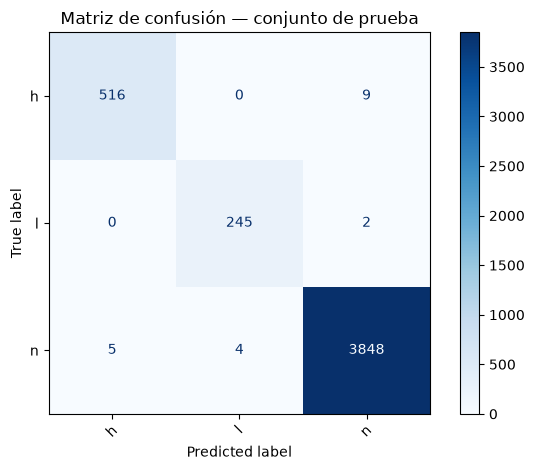

In [5]:
y_pred = model.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
print(f'Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}')
print('\nInforme por clase:')
print(classification_report(y_test, y_pred, labels=np.arange(len(label_encoder.classes_)), target_names=label_encoder.classes_, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    display_labels=label_encoder.classes_,
    cmap='Blues', xticks_rotation=45, values_format='d'
)
plt.title('Matriz de confusión — conjunto de prueba')
plt.tight_layout()
plt.show()

Accuracy 0,997: casi perfecto prediciendo la confianza del sensor con datos cotidianos. No es un hallazgo sobre fuego — es la confirmación de que el pipeline funciona y de que la confianza del sensor deja huella en variables normales. La matriz se lee por la diagonal: casi todo cae en su casilla. Conclusión: andamiaje válido, referencia inútil.

# 7 — PCA para explorar la reducción de columnas CLC

Este análisis localiza todas las columnas cuyo nombre comienza por `clc_`. Como las clases CLC son códigos categóricos, primero se aplica codificación one-hot; introducir los códigos directamente como números haría que PCA interpretara distancias ordinales que no necesariamente existen. A continuación se aplica PCA a esas categorías codificadas.

El notebook informa cuántos componentes hacen falta para conservar el 90% y el 95% de la varianza de las columnas CLC, muestra la varianza acumulada y permite inspeccionar qué columnas originales contribuyen más a los componentes. Si el CSV supera 20.000 filas, se ajusta PCA sobre una muestra reproducible de 20.000 filas para mantener el análisis manejable. El resultado es exploratorio; la decisión final depende del modelo y de la interpretación que se quiera conservar.

### 7.1 — Detección de columnas CLC

Localiza las `clc_*`; informa tipos, distintos y faltantes.

In [6]:

df = load_csv("data/processed/expanded/firms_spain_final_lags_index.csv")
clc_cols = [col for col in df.columns if col.lower().startswith('clc_')]
if not clc_cols:
    raise ValueError('No se encontraron columnas cuyo nombre empiece por clc_.')

print(f'Filas en el CSV: {len(df):,}')
print(f'Columnas CLC detectadas ({len(clc_cols)}): {clc_cols}')
display(pd.DataFrame({
    'tipo': df[clc_cols].dtypes.astype(str),
    'valores_distintos': df[clc_cols].nunique(dropna=True),
    'faltantes': df[clc_cols].isna().sum()
}))


Filas en el CSV: 23,142
Columnas CLC detectadas (10): ['clc_class', 'clc_class_N', 'clc_class_S', 'clc_class_W', 'clc_class_E', 'clc_class_NW', 'clc_class_NE', 'clc_class_SW', 'clc_class_SE', 'clc_uniform_surroundings']


,tipo,valores_distintos,faltantes
clc_class,int64,9,0
clc_class_N,int64,10,0
clc_class_S,int64,10,0
clc_class_W,int64,10,0
clc_class_E,int64,10,0
clc_class_NW,int64,10,0
clc_class_NE,int64,10,0
clc_class_SW,int64,10,0
clc_class_SE,int64,10,0
clc_uniform_surroundings,bool,2,0


Inventario de columnas de suelo en el CSV antes de codificarlas: cuántas hay, cuántos valores distintos toma cada una y cuántos huecos. Es el 'antes' de la compresión.

## Codificación y ajuste de PCA

Los faltantes se conservan como una categoría explícita (`SIN_DATO`). El codificador se ajusta con todas las filas para conocer las categorías presentes; PCA se ajusta con una muestra de hasta 20.000 filas. One-hot produce una matriz dispersa primero y se convierte a matriz densa solo para la muestra usada por PCA.

### 7.2 — One-hot y ajuste

Clases a texto (+SIN_DATO); PCA en muestra de 20.000.

In [7]:
MAX_FILAS_PCA = 20_000

# Convertir todas las clases a texto previene que etiquetas mixtas causen errores.
X_cat = df[clc_cols].astype('string').fillna('SIN_DATO').astype(str)
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:  # compatibilidad con versiones anteriores de scikit-learn
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=True)

encoder.fit(X_cat)
n_fit = min(len(X_cat), MAX_FILAS_PCA)
X_sample_cat = X_cat.sample(n=n_fit, random_state=42)
X_sample_sparse = encoder.transform(X_sample_cat)
X_sample = X_sample_sparse.toarray()

n_components = min(X_sample.shape[0], X_sample.shape[1])
pca = PCA(n_components=n_components, svd_solver='full', random_state=42)
scores = pca.fit_transform(X_sample)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

def components_for(threshold):
    reached = np.flatnonzero(cumulative >= threshold)
    return int(reached[0] + 1) if len(reached) else None

n90, n95 = components_for(0.90), components_for(0.95)
n_encoded = X_sample.shape[1]
print(f'Columnas CLC originales: {len(clc_cols)}')
print(f'Variables one-hot: {n_encoded}')
print(f'Filas usadas para ajustar PCA: {n_fit:,}')
print(f'Componentes para >=90% de varianza: {n90}')
print(f'Componentes para >=95% de varianza: {n95}')
if n95 is not None:
    print(f'Reducción de {n_encoded} variables one-hot a {n95} componentes para conservar >=95% de varianza.')

variance_table = pd.DataFrame({
    'componente': np.arange(1, len(explained) + 1),
    'varianza_individual': explained,
    'varianza_acumulada': cumulative
})
display(variance_table.head(20))

Columnas CLC originales: 10
Variables one-hot: 91
Filas usadas para ajustar PCA: 20,000
Componentes para >=90% de varianza: 17
Componentes para >=95% de varianza: 30
Reducción de 91 variables one-hot a 30 componentes para conservar >=95% de varianza.


,componente,varianza_individual,varianza_acumulada
0,1,0.232348,0.232348
1,2,0.149514,0.381862
2,3,0.122361,0.504223
3,4,0.112411,0.616634
4,5,0.093031,0.709665
5,6,0.064266,0.773931
6,7,0.048195,0.822126
7,8,0.014662,0.836788
8,9,0.012879,0.849667
9,10,0.009853,0.859520


Las 91 columnas one-hot se comprimen: con 29 basta para el 95 % de la información (17 para el 90 %). Lectura: el suelo vecinal es muy redundante — los vecinos se parecen entre sí.

### 7.3 — Varianza explicada

Scree y acumulada con umbrales 90%/95%.

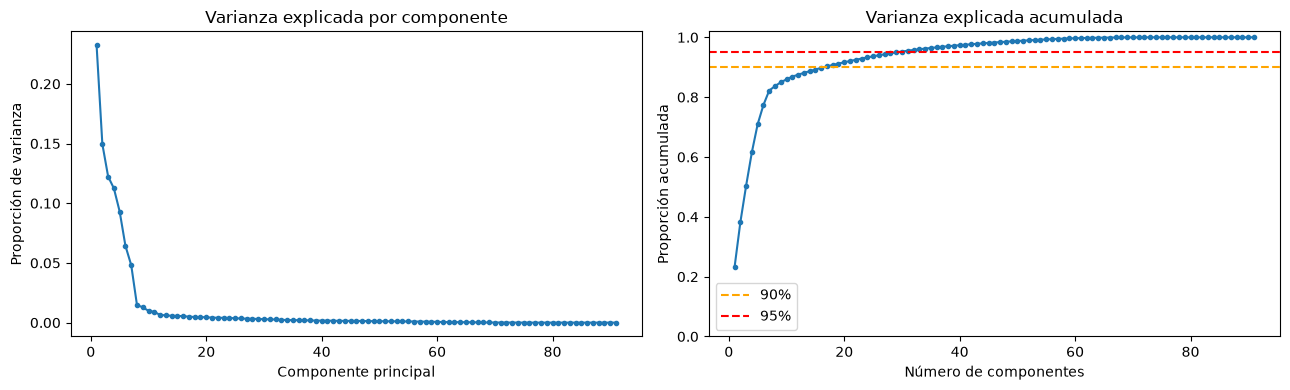

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(variance_table['componente'], variance_table['varianza_individual'], marker='o', ms=3)
axes[0].set(title='Varianza explicada por componente', xlabel='Componente principal', ylabel='Proporción de varianza')
axes[1].plot(variance_table['componente'], variance_table['varianza_acumulada'], marker='o', ms=3)
axes[1].axhline(.90, color='orange', linestyle='--', label='90%')
axes[1].axhline(.95, color='red', linestyle='--', label='95%')
axes[1].set(title='Varianza explicada acumulada', xlabel='Número de componentes', ylabel='Proporción acumulada', ylim=(0, 1.02))
axes[1].legend()
plt.tight_layout()
plt.show()

Dos curvas: varianza por componente y acumulada, con las líneas del 90/95 %. El codo dice dónde deja de compensar añadir componentes. Conclusión visual del punto anterior.

## Contribuciones de las columnas CLC

Para cada componente se suman las magnitudes absolutas de las cargas de sus categorías one-hot, agrupadas por la columna CLC original. Es una ayuda para interpretar qué campos aportan más a cada componente; las cargas individuales dependen de la categoría concreta. La última celda deja en memoria las puntuaciones PCA de la muestra, reducidas al menor número de componentes que conserva el 95% (o todos si no se alcanza ese umbral).

### 7.4 — Contribuciones y muestra reducida

Suma de |cargas| por columna CLC; `reduced_sample` solo en memoria.

In [9]:
encoded_names = encoder.get_feature_names_out(clc_cols)
# El orden de get_feature_names_out sigue categorías_ por cada columna.
encoded_to_source = []
for col, categories in zip(clc_cols, encoder.categories_):
    encoded_to_source.extend([col] * len(categories))

n_show = min(5, pca.components_.shape[0])
loading_rows = []
for pc in range(n_show):
    abs_loadings = np.abs(pca.components_[pc])
    summary = pd.Series(abs_loadings).groupby(encoded_to_source).sum().sort_values(ascending=False)
    for source_col, value in summary.head(5).items():
        loading_rows.append({'componente': f'PC{pc+1}', 'columna_CLC': source_col, 'suma_cargas_absolutas': value})
display(pd.DataFrame(loading_rows))

# DataFrame reducido de la muestra usada por PCA.
n_keep = n95 if n95 is not None else scores.shape[1]
reduced_sample = pd.DataFrame(
    scores[:, :n_keep],
    index=X_sample_cat.index,
    columns=[f'PC{i+1}' for i in range(n_keep)]
)
print(f'Muestra reducida: {reduced_sample.shape[0]:,} filas x {reduced_sample.shape[1]} componentes')
reduced_sample.head()

,componente,columna_CLC,suma_cargas_absolutas
0,PC1,clc_class,0.637424
1,PC1,clc_class_E,0.614118
2,PC1,clc_class_W,0.613222
3,PC1,clc_class_N,0.612818
4,PC1,clc_class_S,0.610819
5,PC2,clc_class,0.644757
6,PC2,clc_class_E,0.644229
7,PC2,clc_class_W,0.640007
8,PC2,clc_class_S,0.639375
9,PC2,clc_class_N,0.638332


Muestra reducida: 20,000 filas x 30 componentes


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30
18466,-0.587265,-1.080025,-1.625590,-0.933754,-0.518124,-0.476026,-0.658671,-0.675996,-0.296770,-0.042041,...,0.138054,-0.348004,-0.399453,0.352196,0.236191,-0.011388,0.228553,0.041499,-0.147712,-0.040430
2898,2.298589,0.206491,0.138626,-0.081029,-0.074158,-0.148355,-0.279849,-0.000947,0.000100,-0.001652,...,0.010225,-0.000450,0.000531,0.002996,0.002412,0.006882,-0.010069,-0.002575,-0.015730,-0.012294
19027,-0.988007,-0.922250,2.322205,-1.028493,-0.470245,-0.316897,-0.018835,0.003327,-0.004121,0.001489,...,0.001897,0.005365,-0.008421,0.001248,-0.001071,-0.001340,0.006157,0.009384,-0.004285,0.001752
5186,-0.755162,-0.313785,0.136928,0.485245,2.713234,-0.632419,-0.532966,0.001081,0.002652,0.009836,...,-0.018997,-0.007835,-0.012759,-0.016913,0.000174,-0.008643,0.022325,-0.000901,0.000933,0.005423
15295,-0.937964,-1.242542,-1.846735,-1.039808,-0.571777,-0.517835,-0.698072,-0.004806,-0.002703,-0.003102,...,0.004170,0.004149,0.007110,0.001967,0.002363,0.006195,-0.019617,-0.004129,-0.001929,-0.014054


Para los 5 primeros componentes, qué columnas de suelo mandan (suma de cargas absolutas): el píxel central y los vecinos cardinales pesan casi igual — la dirección no aporta. La 'muestra reducida' es el dataset ya comprimido a 29 números por fila.

# 8 — Variables normalizadas

Este notebook carga nuestro dataframe y normaliza las variables numéricas continuas con **Z-score** (`StandardScaler`): centra cada variable alrededor de 0 y la escala para que su desviación típica sea aproximadamente 1.

Se excluyen identificadores y códigos numéricos categóricos como `type`, `sensor`, `acq_time` y las columnas `clc_`; normalizar esos códigos les daría un significado de magnitud que no tienen. Las variables categóricas y los valores faltantes se conservan. El CSV de salida es una copia donde solo se sustituyen las columnas seleccionadas.

La celda de exportación ajusta el escalador al conjunto completo porque genera una versión normalizada descriptiva del archivo. Si se usa para evaluar un modelo predictivo, hay que dividir primero entrenamiento/prueba y ajustar el escalador solo con entrenamiento, como muestra la última sección.

### 8.1 — Carga

Carga el CSV con índice; informa filas×columnas.

In [10]:

df = load_csv("data/processed/expanded/firms_spain_final_lags_index.csv")
print(f'{len(df):,} filas y {df.shape[1]} columnas')
df.head()


23,142 filas y 62 columnas

,detection_id,latitude,longitude,brightness,scan,acq_date,acq_time,brightness_ir,frp,daynight,...,ratio_prevencion_extincion,euros_prevencion_por_ha,euros_extincion_por_ha,potencial_propagacion,indice_riesgo_meteo,estres_termico_vegetacion,indice_riesgo_meteo_log,indice_meteorologico,componentes_disponibles,nivel_relativo
0,0,43.1262,-4.0911,316.0,1.1,2023-01-01,221,273.7,20.4,N,...,0.492424,18.055556,36.666667,12.783511,32.892090,0.223829,3.523182,44.756179,6,Medio
1,1,39.2047,-1.7606,304.4,1.0,2023-01-01,1326,286.6,6.2,D,...,0.857143,33.333333,38.888889,5.086914,23.380942,0.298169,3.193802,41.538221,6,Medio
2,2,42.3885,-2.7282,301.2,3.1,2023-01-03,1008,279.5,40.0,D,...,0.512195,18.529412,36.176471,0.960729,2.737120,0.075261,1.318315,17.419735,6,Bajo
3,3,38.5923,-1.0710,304.7,1.1,2023-01-03,1313,291.0,6.3,D,...,0.467742,28.431373,60.784314,1.559968,33.912346,0.251509,3.552841,39.445273,6,Medio
4,4,38.7134,-0.7309,302.0,1.0,2023-01-03,1313,288.8,5.0,D,...,0.595092,74.615385,125.384615,3.824963,24.518993,0.218192,3.239423,29.330978,6,Bajo


Base del bloque 8: el índice de 02a (forma impresa en la primera salida). Todo lo que sigue (selección, z-score, ejemplo train-only) parte de aquí.

## Seleccionar variables

Además de las columnas CLC, se excluyen columnas que son códigos o etiquetas, aunque estén almacenadas como números. Las variables booleanas también quedan fuera. La lista de exclusión se puede ajustar según el uso posterior.
Además de códigos y satélite, quedan fuera del escalado (pero siguen como predictores sin escalar): grados (`latitude`, `longitude`) y pares seno/coseno (`month_*`, `day_of_year_*`, `wd_*`, derivado este último de la dirección cruda). El z-score independiente los deformaría; la lista exacta vive en `UNSCALED`/`scale_cols` de la celda 8.2.

### 8.2 — Selección de variables

Numéricas continuas excluyendo códigos CLC y booleanos. Excluye códigos, duplicados, circulares crudas, constante y satélite; define `numeric_cols` (modelado), `UNSCALED` y `scale_cols` (scaler).

In [11]:
# La dirección cruda es circular (359° ~ 1°): se expande a wd_sin/wd_cos
# como en el PCA; la cruda queda fuera de todo lo que sigue.
_wd = AddWindCircular().fit_transform(df[["wind_direction_10m"]])
df[["wd_sin", "wd_cos"]] = _wd

# Códigos, duplicados, circulares crudas, constante y satélite fuera.
# También indice_meteorologico/nivel_relativo: funciones deterministas de
# los predictores meteo, excluidas del modelado por occurrence.py.
exclude = {'type', 'sensor', 'acq_time', 'is_day', 'year',
           'month', 'day_of_year', 'componentes_disponibles',
           'indice_meteorologico', 'nivel_relativo',
           'rain', 'wind_direction_10m',
           'brightness', 'scan', 'brightness_ir', 'frp', 'confidence_num'}
exclude.update(c for c in df.columns if c.lower().startswith('clc_'))
numeric_cols = [
    c for c in df.select_dtypes(include=[np.number]).columns
    if c not in exclude and not pd.api.types.is_bool_dtype(df[c])
]
# Sin escalar (pero sí predictores): grados y pares seno/coseno ya están
# en escala comparable; el z-score independiente los deformaría.
UNSCALED = {'latitude', 'longitude', 'month_sin', 'month_cos',
            'day_of_year_sin', 'day_of_year_cos', 'wd_sin', 'wd_cos'}
scale_cols = [c for c in numeric_cols if c not in UNSCALED]
if not numeric_cols:
    raise ValueError('No se encontraron variables numéricas continuas para normalizar.')
print(f'Variables numéricas ({len(numeric_cols)}), a escalar ({len(scale_cols)}):')
print(numeric_cols)
display(pd.DataFrame({
    'faltantes': df[numeric_cols].isna().sum(),
    'valores_distintos': df[numeric_cols].nunique(dropna=True),
    'media_original': df[numeric_cols].mean(),
    'desviacion_original': df[numeric_cols].std()
}).sort_index())


Variables numéricas (33), a escalar (25):
['detection_id', 'latitude', 'longitude', 'temperature_2m', 'precipitation', 'surface_pressure', 'relative_humidity_2m', 'wind_speed_10m', 'wind_gusts_10m', 'et0_fao_evapotranspiration', 'shortwave_radiation', 'boundary_layer_height', 'vapour_pressure_deficit', 'soil_moisture_0_to_7cm', 'soil_moisture_7_to_28cm', 'prevention_current', 'prevention_prev3', 'extinction_prev3', 'riesgo_antropico_alto', 'month_sin', 'month_cos', 'day_of_year_sin', 'day_of_year_cos', 'sup_forestal_ha', 'ratio_prevencion_extincion', 'euros_prevencion_por_ha', 'euros_extincion_por_ha', 'potencial_propagacion', 'indice_riesgo_meteo', 'estres_termico_vegetacion', 'indice_riesgo_meteo_log', 'wd_sin', 'wd_cos']


,faltantes,valores_distintos,media_original,desviacion_original
boundary_layer_height,0,5480,7.882452e+02,7.127003e+02
day_of_year_cos,0,365,-2.612294e-01,5.752183e-01
day_of_year_sin,0,365,7.992751e-02,7.710607e-01
detection_id,0,23142,1.157050e+04,6.680664e+03
estres_termico_vegetacion,0,17679,5.499905e-01,5.439457e-01
et0_fao_evapotranspiration,0,21415,2.664891e-01,2.753443e-01
euros_extincion_por_ha,0,34,8.798577e+01,5.305416e+01
euros_prevencion_por_ha,0,32,5.314165e+01,2.816582e+01
extinction_prev3,0,33,1.420129e+02,8.132485e+01
indice_riesgo_meteo,0,17670,1.371007e+02,2.795822e+02


Las 32 numéricas candidatas y cuáles 24 se escalan: fuera códigos, satélite, constantes y duplicados; grados y pares seno/coseno pasan sin escalar porque ya están en escala comparable (un z-score los deformaría).

## Aplicar Z-score y guardar copia

`StandardScaler` conserva los NaN. No imputa faltantes: si el siguiente modelo los requiere, habrá que imputarlos dentro del pipeline de entrenamiento.
Esta copia es descriptiva; para modelar, ajustar el scaler solo en train (ver 8.4).

### 8.3 — Z-score y guardado

Estandariza las seleccionadas (conserva NaN) y guarda la copia.

In [12]:
scaler = StandardScaler()
df_norm = df.copy()
df_norm[scale_cols] = scaler.fit_transform(df[scale_cols])

comparison = pd.DataFrame({
    'media_normalizada': df_norm[scale_cols].mean(),
    'desviacion_normalizada': df_norm[scale_cols].std(),
    'faltantes': df_norm[scale_cols].isna().sum()
})
display(comparison)

output_path = 'data/processed/expanded/firms_spain_final_normalized.csv'
save_csv(df_norm, output_path)
print(f'Archivo normalizado guardado en: {output_path}')
df_norm.head()


,media_normalizada,desviacion_normalizada,faltantes
detection_id,0.000000e+00,1.000022,0
temperature_2m,-2.161534e-16,1.000022,0
precipitation,-2.456288e-18,1.000022,0
surface_pressure,1.552374e-15,1.000022,0
relative_humidity_2m,4.912576e-17,1.000022,0
wind_speed_10m,1.719402e-16,1.000022,0
wind_gusts_10m,-1.965030e-17,1.000022,0
et0_fao_evapotranspiration,-7.860122e-17,1.000022,0
shortwave_radiation,7.860122e-17,1.000022,0
boundary_layer_height,4.912576e-17,1.000022,0


Archivo normalizado guardado en: data/processed/expanded/firms_spain_final_normalized.csv


,detection_id,latitude,longitude,brightness,scan,acq_date,acq_time,brightness_ir,frp,daynight,...,euros_extincion_por_ha,potencial_propagacion,indice_riesgo_meteo,estres_termico_vegetacion,indice_riesgo_meteo_log,indice_meteorologico,componentes_disponibles,nivel_relativo,wd_sin,wd_cos
0,-1.731976,43.1262,-4.0911,316.0,1.1,2023-01-01,221,273.7,20.4,N,...,-0.967317,-0.200624,-0.372738,-0.599634,-0.242970,44.756179,6,Medio,0.035331,-0.999376
1,-1.731826,39.2047,-1.7606,304.4,1.0,2023-01-01,1326,286.6,6.2,D,...,-0.925431,-0.589692,-0.406758,-0.462963,-0.460126,41.538221,6,Medio,0.999651,0.026413
2,-1.731677,42.3885,-2.7282,301.2,3.1,2023-01-03,1008,279.5,40.0,D,...,-0.976557,-0.798274,-0.480597,-0.872770,-1.696612,17.419735,6,Bajo,-0.865090,0.501616
3,-1.731527,38.5923,-1.0710,304.7,1.1,2023-01-03,1313,291.0,6.3,D,...,-0.512722,-0.767982,-0.369088,-0.548746,-0.223416,39.445273,6,Medio,0.706367,-0.707845
4,-1.731377,38.7134,-0.7309,302.0,1.0,2023-01-03,1313,288.8,5.0,D,...,0.704934,-0.653485,-0.402687,-0.609998,-0.430048,29.330978,6,Bajo,0.189775,0.981828


Solo la ruta del fichero guardado. El normalizado es una copia descriptiva con el scaler ajustado en todo el dataset: vale para mirar, no para ajustar modelos (eso es el 8.4).

## Ejemplo correcto para evaluación predictiva

Al evaluar un modelo, ajustar el escalador con todo el CSV filtraría información del conjunto de prueba. En este ejemplo se divide primero y se aprende la media/desviación únicamente en entrenamiento; después se transforma prueba con esos mismos parámetros. Para una red neuronal, lo ideal es integrar este escalador en un `Pipeline`.

### 8.4 — Ejemplo train-only

Escalador ajustado solo en entrenamiento; patrón para evaluación. Además elimina las variables de satélite antes de dividir.

In [13]:
X = df[numeric_cols]

# (recordatorio del guardián: SATELLITE_BLOCKLIST ya quedó fuera en 8.2;
# se repite aquí por si la selección cambia en el futuro.)
print("Variables de satélite excluidas:")
print(sorted(c for c in SATELLITE_BLOCKLIST if c in X.columns))
X = X.drop(columns=[c for c in SATELLITE_BLOCKLIST if c in X.columns])
print(f"Predictores: {len(X.columns)}")
X_train, X_test = train_test_split(X, test_size=0.20, random_state=42)
scaler_train = StandardScaler()
X_train_norm = pd.DataFrame(scaler_train.fit_transform(X_train[scale_cols]), columns=scale_cols, index=X_train.index)
X_test_norm = pd.DataFrame(scaler_train.transform(X_test[scale_cols]), columns=scale_cols, index=X_test.index)
# Las no escaladas (grados, seno/coseno) pasan tal cual para no deformarlas.
for _norm, _raw in ((X_train_norm, X_train), (X_test_norm, X_test)):
    for _c in X.columns:
        if _c not in scale_cols:
            _norm[_c] = _raw[_c].to_numpy()
X_train_norm = X_train_norm[X.columns]
X_test_norm = X_test_norm[X.columns]
print('Filas entrenamiento:', len(X_train_norm), '| filas prueba:', len(X_test_norm))
display(X_train_norm.head())


Variables de satélite excluidas:
[]
Predictores: 33
Filas entrenamiento: 18513 | filas prueba: 4629


,detection_id,latitude,longitude,temperature_2m,precipitation,surface_pressure,relative_humidity_2m,wind_speed_10m,wind_gusts_10m,et0_fao_evapotranspiration,...,sup_forestal_ha,ratio_prevencion_extincion,euros_prevencion_por_ha,euros_extincion_por_ha,potencial_propagacion,indice_riesgo_meteo,estres_termico_vegetacion,indice_riesgo_meteo_log,wd_sin,wd_cos
8306,-0.488205,38.29279,-6.74962,-1.469482,-0.07776,1.059920,1.090296,-0.248457,-0.755510,-0.902920,...,0.317388,-0.041456,-0.923577,-0.852498,-0.723822,-0.458899,-0.859522,-1.050202,0.984674,0.174406
14491,0.436529,38.89120,-0.23391,-0.731509,-0.07776,0.837513,-0.025685,2.190658,1.546697,-0.549483,...,-0.558152,-0.288309,0.761506,0.704405,0.178887,0.365607,-0.557648,1.046456,-0.999057,0.043419
9963,-0.240463,42.28221,-6.69773,-1.351365,-0.07776,-1.519607,1.887719,-0.045933,0.594477,-0.951154,...,1.818313,-0.180644,-1.332532,-1.177796,-0.797740,-0.480725,-0.867612,-1.676776,-0.877710,-0.479192
8349,-0.481776,42.60077,-6.20868,-1.115441,-0.07776,-0.886307,-0.365068,0.067701,0.186435,-0.037156,...,1.818313,-0.180644,-1.332532,-1.177796,-0.431490,-0.411041,-0.620002,-0.488937,0.845396,-0.534139
293,-1.686246,43.15100,-3.83910,-0.452708,-0.07776,0.643854,0.967004,-0.529907,-0.536445,-0.162625,...,-1.146014,-0.926845,-1.241675,-0.963935,-0.655358,-0.456949,-0.632618,-1.015049,0.504691,0.863300


La lección del bloque en un ejemplo: el scaler se ajusta solo en train y se aplica en test; satélite fuera; grados y seno/coseno pasan tal cual. Así se evalúa sin hacer trampa.